# LAB 09 — Tokenization và label alignment
Tokenizer **`bert-base-cased`** (WordPiece, phân biệt hoa thường, vocabulary 28,996) trên CoNLL-2003. Dataset gán nhãn theo **word**, Transformer làm việc trên **subword token** → cần alignment.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from collections import Counter, defaultdict
from transformers import AutoTokenizer
from datasets import load_dataset
from ner_utils import LABELS, LABEL2ID, IGNORE, get_entities, align_labels
warnings.filterwarnings("ignore")
tok = AutoTokenizer.from_pretrained("bert-base-cased")
ds = load_dataset("eriktks/conll2003", revision="refs/convert/parquet")
W = {sp: [list(x) for x in ds[sp]["tokens"]] for sp in ("train", "validation", "test")}
T = {sp: [[LABELS[i] for i in x] for x in ds[sp]["ner_tags"]] for sp in ("train", "validation", "test")}
print({sp: len(v) for sp, v in W.items()})

C:\Users\dinhb\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 14041, 'validation': 3250, 'test': 3453}


## 16. Core — `tokenizer(words, is_split_into_words=True)` → `word_ids` → alignment → token labels

In [2]:
words = ["Elon", "Musk", "founded", "SpaceX", "in", "California", "."]; tags = ["B-PER", "I-PER", "O", "B-ORG", "O", "B-LOC", "O"]
tokens = tok(words, is_split_into_words=True, truncation=True, padding=True)
wid = tokens.word_ids(); ids_ = [LABEL2ID[t] for t in tags]
show = lambda labs: [LABELS[l] if l != IGNORE else "−100" for l in labs]
display(pd.DataFrame({"token": tok.convert_ids_to_tokens(tokens["input_ids"]), "input_id": tokens["input_ids"], "attention_mask": tokens["attention_mask"],
                      "word_id": wid, "word label": [tags[w] if w is not None else "" for w in wid],
                      "Strategy A": show(align_labels(wid, ids_, "first")), "Strategy B": show(align_labels(wid, ids_, "all"))}).T)
print("keys:", list(tokens.keys()))

,0,1,2,3,4,5,6,7,8,9,10,11
token,[CLS],El,##on,Mu,##sk,founded,Space,##X,in,California,.,[SEP]
input_id,101,2896,1320,19569,5276,1771,4525,3190,1107,1756,119,102
attention_mask,1,1,1,1,1,1,1,1,1,1,1,1
word_id,NaN,0.0,0.0,1.0,1.0,2.0,3.0,3.0,4.0,5.0,6.0,NaN
word label,,B-PER,B-PER,I-PER,I-PER,O,B-ORG,B-ORG,O,B-LOC,O,
Strategy A,−100,B-PER,−100,I-PER,−100,O,B-ORG,−100,O,B-LOC,O,−100
Strategy B,−100,B-PER,I-PER,I-PER,I-PER,O,B-ORG,I-ORG,O,B-LOC,O,−100


keys: ['input_ids', 'token_type_ids', 'attention_mask']


- `word_ids()` cho biết mỗi subword thuộc word thứ mấy; `None` là [CLS]/[SEP]/[PAD].
- **Strategy A (dùng trong lab):** subword đầu tiên của word nhận nhãn của word, các subword sau (##on, ##sk, ##X) và special token nhận −100 nên không vào loss. Mỗi word đóng góp đúng một lần, khớp annotation gốc, và lúc dự đoán lấy nhãn của subword đầu làm nhãn của word.
- Strategy B lan truyền nhãn: subword sau của B-PER thành I-PER. Hai cách được so sánh bằng thực nghiệm trong `ner_finetuning.ipynb`.

## 17. Experiment 1 — Tokenization analysis (30 câu test chọn ngẫu nhiên, seed 2026)
R = #subword tokens / #words (không tính [CLS], [SEP]). "subword splits" = số word bị tách thành ≥ 2 token.

In [3]:
def pieces(w): return tok.tokenize(w)
rng = np.random.RandomState(2026); idx = rng.choice(len(W["test"]), 30, replace=False); rows = []
for i in idx:
    ws, ts = W["test"][i], T["test"][i]; n_tok = [len(pieces(w)) for w in ws]
    rows.append({"test_id": int(i), "# words": len(ws), "# tokens": sum(n_tok), "# subword splits": sum(n > 1 for n in n_tok), "R": round(sum(n_tok) / len(ws), 2),
                 "# entity words": sum(t != "O" for t in ts), "câu": " ".join(ws)[:80]})
t30 = pd.DataFrame(rows).set_index("test_id"); display(t30)
med = t30["# words"].median(); short, long_ = t30[t30["# words"] <= med], t30[t30["# words"] > med]
print(f"30 câu: R = {t30['# tokens'].sum() / t30['# words'].sum():.3f} | câu ngắn (≤ {med:.0f} word): R = {short['# tokens'].sum() / short['# words'].sum():.3f} | câu dài: R = {long_['# tokens'].sum() / long_['# words'].sum():.3f}")

,# words,# tokens,# subword splits,R,# entity words,câu
test_id,,,,,,
2982,10,10,0,1.00,3,Queens Park Rangers 22 7 7 8 25 28 28
635,15,26,5,1.73,6,RKC Waalwijk 1 ( Starbuck 76 ) Willem II Tilbu...
950,55,61,4,1.11,4,Company President Jean van Boxmeer told Reuter...
3082,4,4,0,1.00,2,Chelsea 2 Everton 2
3039,8,8,0,1.00,1,Hereford 22 6 5 11 23 31 23
2872,4,7,1,1.75,1,Kanchelskis 28 ) .
580,8,8,0,1.00,1,Utrecht 18 4 10 4 26 24 22
2259,30,36,4,1.20,8,"On Friday , some students told Reuters that th..."
3373,5,8,1,1.60,3,NY RANGERS 6 Toronto 5


30 câu: R = 1.171 | câu ngắn (≤ 8 word): R = 1.271 | câu dài: R = 1.147


In [4]:
# Trên toàn bộ test set: entity vs non-entity, và theo loại word
cnt = defaultdict(lambda: [0, 0, 0])            # nhóm -> [#words, #tokens, #split]
def group(w, t):
    if t != "O": return "entity: " + t[2:]
    if any(c.isdigit() for c in w): return "non-entity: số"
    if not w.isalnum(): return "non-entity: dấu câu/ký hiệu"
    if w[0].isupper(): return "non-entity: viết hoa"
    return "non-entity: chữ thường"
for ws, ts in zip(W["test"], T["test"]):
    for w, t in zip(ws, ts):
        n = len(pieces(w)); g = group(w, t)
        for k in (g, "ENTITY (tất cả)" if t != "O" else "NON-ENTITY (tất cả)"):
            cnt[k][0] += 1; cnt[k][1] += n; cnt[k][2] += n > 1
tg = pd.DataFrame([{"nhóm": k, "# words": v[0], "R = tokens/words": round(v[1] / v[0], 3), "% word bị tách": round(v[2] / v[0] * 100, 1)} for k, v in cnt.items()]).set_index("nhóm").sort_values("R = tokens/words", ascending=False)
display(tg)
split_words = Counter()
for ws in W["test"]:
    for w in ws:
        if len(pieces(w)) >= 4: split_words[w] += 1
print("ví dụ word bị tách thành ≥ 4 subword:", [(w, " ".join(pieces(w))) for w, _ in split_words.most_common(15)])
for w in ["Washington", "Germany", "Clinton", "Yeltsin", "Akrem", "Middlesbrough", "Wednesday", "1996-08-30", "playing", "U.S."]:
    print(f"  {w:14s} → {' '.join(pieces(w))}")

,# words,R = tokens/words,% word bị tách
nhóm,,,
entity: PER,2773,2.055,59.9
entity: ORG,2496,1.936,45.2
ENTITY (tất cả),8112,1.915,45.3
non-entity: số,5874,1.820,33.9
entity: LOC,1925,1.775,31.2
entity: MISC,918,1.730,31.2
non-entity: viết hoa,2893,1.704,31.5
NON-ENTITY (tất cả),38323,1.251,12.0
non-entity: dấu câu/ký hiệu,6513,1.189,11.1


ví dụ word bị tách thành ≥ 4 subword: [('1996-12-06', '1996 - 12 - 06'), ('U.S.', 'U . S .'), ('1996-12-07', '1996 - 12 - 07'), ('SOCCER', 'S ##OC ##CE ##R'), ('DIVISION', 'D ##I ##VI ##SI ##ON'), ('LONDON', 'L ##ON ##D ##ON'), ('RESULTS', 'R ##ES ##U ##LT ##S'), ('STANDINGS', 'ST ##AN ##DI ##NG ##S'), ('Bre-X', 'B ##re - X'), ('U.N.', 'U . N .'), ('CHICAGO', 'CH ##IC ##AG ##O'), ('WASHINGTON', 'WA ##S ##H ##ING ##TO ##N'), ('CRICKET', 'CR ##IC ##KE ##T'), ('CONFERENCE', 'CO ##NF ##ER ##EN ##CE'), ('DETROIT', 'DE ##TR ##O ##IT')]
  Washington     → Washington
  Germany        → Germany
  Clinton        → Clinton
  Yeltsin        → Ye ##lts ##in
  Akrem          → A ##k ##rem
  Middlesbrough  → Middlesbrough
  Wednesday      → Wednesday
  1996-08-30     → 1996 - 08 - 30
  playing        → playing
  U.S.           → U . S .


**Nhận xét Experiment 1:**
- Trên 30 câu, R = 1.17 token/word; câu ngắn (≤ 8 word) có R cao hơn (1.27) so với câu dài (1.15) vì câu ngắn trong CoNLL thường là dòng tiêu đề/kết quả thể thao toàn tên riêng và số ("NY RANGERS 6 Toronto 5"), còn câu dài là văn xuôi có nhiều từ thường.
- **Entity bị tách nhiều hơn hẳn:** entity word R = 1.92 (45% bị tách) so với non-entity 1.25 (12%); PER cao nhất (R 2.06, 60% bị tách) vì tên người nước ngoài hiếm (Yeltsin → Ye ##lts ##in), rồi ORG (1.94). Từ thường chữ thường gần như không bị tách (4%).
- **Loại từ hay bị tách:** tên riêng hiếm (người, tổ chức), từ **VIẾT HOA TOÀN BỘ** ở tiêu đề (LONDON → L ##ON ##D ##ON, WASHINGTON thành 6 mảnh: tokenizer *cased* có "Washington" nhưng không có "WASHINGTON"), số/ngày (1996-12-06 → 5 token), viết tắt có dấu chấm (U.S. → U . S .). Những từ phổ biến như "Washington", "Germany", "playing" giữ nguyên một token.
- Hệ quả: entity, đúng phần cần nhận diện, là phần bị chia nhỏ nhất, nên alignment quan trọng đúng ở chỗ khó nhất.

## Thống kê alignment trên toàn bộ dataset (Strategy A)

train: 300,677 token (kể special) | IGNORE 32.3% | câu dài nhất 173 token | câu > 128 token: 1 | > 256: 0


test: 70,367 token (kể special) | IGNORE 34.0% | câu dài nhất 148 token | câu > 128 token: 2 | > 256: 0


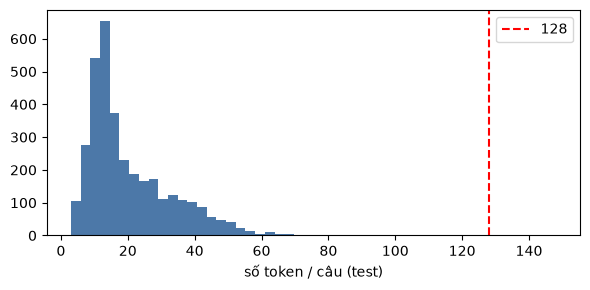

In [5]:
for sp in ("train", "test"):
    enc = tok(W[sp], is_split_into_words=True)
    lens = np.array([len(x) for x in enc["input_ids"]])
    labs = [align_labels(enc.word_ids(i), [LABEL2ID[t] for t in T[sp][i]], "first") for i in range(len(W[sp]))]
    n_ign = sum(l == IGNORE for ls in labs for l in ls); n_all = sum(len(ls) for ls in labs)
    print(f"{sp}: {n_all:,} token (kể special) | IGNORE {n_ign/n_all:.1%} | câu dài nhất {lens.max()} token | câu > 128 token: {(lens > 128).sum()} | > 256: {(lens > 256).sum()}")
plt.figure(figsize=(6, 3)); plt.hist(lens, bins=50, color="#4c78a8"); plt.axvline(128, color="red", ls="--", label="128"); plt.xlabel("số token / câu (test)"); plt.legend(); plt.tight_layout(); plt.show()

Với Strategy A, khoảng 1/3 token (32–34%, gồm [CLS], [SEP] và các mảnh ## sau) nhận −100, không vào loss nhưng vẫn là input và vẫn tham gia attention. Câu dài nhất chỉ 173 token nên dùng max_length 256 không cắt câu nào (128 sẽ cắt 1 câu train và 2 câu test).